# Capstone — mirrors your deployed research paper

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

#### Research Question

What performance archetypes exist across the content inventory, and how can these archetypes help prioritize content for actions such as refreshing, improving, monitoring, or further reviewing pages?

#### Decision Supported

The analysis supports content teams in grouping similar pages by their performance and content characteristics, helping them prioritize review efforts instead of applying the same action to every page.

The clustering results are intended for **decision support**, not as definitive predictions of which pages will succeed or fail.

## 2. Data

### Dataset Release and Source Tables

This analysis uses the 2026 FlyRank ML Internship dataset. Two warehouse tables were used:

- **`dim_content`** — content metadata, including content type, search volume, search intent, word count, and publication-related fields.
- **`fact_content_daily_performance`** — daily content performance metrics, including Google Search Console (GSC) impressions and clicks, and Google Analytics 4 (GA4) sessions.

### Date Window and Analysis Population

Performance data was aggregated for **March 1–31, 2026**. The metadata table contained 519,606 content records, while the March performance aggregation contained 331,437 unique content IDs that matched the metadata.

For clustering, the analysis focused on **176,738 pages with available GSC data for at least one day** during the selected period. Pages without available GSC data were excluded from clustering because their search-performance characteristics could not be reliably assessed.

### Exclusions and Rationale

- **Client names, domains, URLs, and private search queries:** excluded from public reporting to protect confidentiality.
- **Content identifiers:** used internally for joining and evaluation but not exposed in public-facing results.
- **Post-period metadata dates:** excluded as predictive features because they could introduce temporal leakage.
- **GA4 metrics:** not used as core clustering features because availability was limited across the dataset.
- **Publication and deletion status:** reserved for eligibility checks and recommendations rather than used as predictive features.
- **Raw warehouse exports:** not included in the public paper or repository.

The analysis represents one month of observed performance. Its results describe patterns in the selected dataset and should not be interpreted as causal evidence of content-refresh impact or search-engine ranking behavior.

## 3. Methodology

### Clustering Approach

MiniBatch K-Means clustering was used to group content pages according to their search-performance metrics and content characteristics. Candidate cluster counts from K = 2 to K = 8 were compared using inertia and sampled silhouette scores. Four clusters were selected because K = 4 achieved the highest silhouette score among the tested candidates.

### Features

The clustering features included GSC impressions, GSC clicks, click-through rate (CTR), search volume, word count, category count, content type, and main search intent.

Selected skewed numeric features were log-transformed. Missing numeric values were handled using median imputation, numeric features were standardized, and categorical features were imputed and one-hot encoded.

### Baseline

The Week 4 rule-based action score served as the baseline. It assigned content actions using content age and search volume. This baseline is a prioritization heuristic, not ground-truth labels or a validated prediction model.

### Validation Design

Data was split by client using GroupShuffleSplit, with 80% of records allocated to training and 20% to testing. Grouping by client prevented the same client's pages from appearing in both sets. The split used random state 42.

### Leakage Checks

Metadata dates beyond the March 2026 performance window were excluded as model features. Preprocessing must be fitted on training data only and then applied to test data. The final evaluation will use the corrected pipeline and updated results.

In [4]:
# Purpose: Import the libraries needed to access the dataset and inspect Parquet files.
import pandas as pd
import numpy as np
import pyarrow.parquet as pq

from huggingface_hub import hf_hub_download
from datasets import load_dataset

# Purpose: Retrieve the Hugging Face token from the notebook's secure secret storage.
from google.colab import userdata
HF_TOKEN = userdata.get("HF_token")


In [5]:
# Purpose: Download the March 2026 performance Parquet file and inspect
# its metadata without loading the entire table into memory.
fact_path = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    repo_type="dataset",
    filename="fact_content_daily_performance/month=2026-03/data_0.parquet",
    token=HF_TOKEN
)

parquet_file = pq.ParquetFile(fact_path)

print("March file downloaded:", fact_path)
print("Rows in file:", parquet_file.metadata.num_rows)
print("Columns:", parquet_file.schema.names)
print("Row groups:", parquet_file.num_row_groups)


fact_content_daily_performance/month=202(…): reconstructing file:   0%|          |  0.00B /  124MB            

fact_content_daily_performance/month=202(…): downloading bytes:           |  0.00B            

March file downloaded: /root/.cache/huggingface/hub/datasets--FlyRank--internship-warehouse/snapshots/50cbf7c3909d07be4d1b5906b4d09e882e5acbf2/fact_content_daily_performance/month=2026-03/data_0.parquet
Rows in file: 9841378
Columns: ['report_date', 'client_hash_id', 'content_hash_id', 'client_has_gsc', 'client_has_ga4', 'gsc_data_available', 'ga4_data_available', 'gsc_impressions', 'gsc_clicks', 'gsc_sum_position', 'gsc_avg_position', 'ga4_pageviews', 'ga4_sessions', 'ga4_users', 'ga4_engaged_sessions', 'ga4_total_engagement_sec', 'sessions_organic', 'sessions_direct', 'sessions_referral', 'sessions_social', 'sessions_paid', 'sessions_ai', 'ai_chatgpt', 'ai_perplexity', 'ai_gemini', 'ai_copilot', 'ai_claude', 'ai_meta', 'ai_other', 'scroll_events']
Row groups: 85


In [6]:
# Purpose: Load the content metadata table needed to describe and join pages.
dim_content = load_dataset(
    "FlyRank/internship-warehouse",
    "dim_content",
    split="train",
    token=HF_TOKEN
).to_pandas()

print("dim_content shape:", dim_content.shape)
print("Available columns:", dim_content.columns.tolist())


README.md:   0%|          | 0.00/3.04k [00:00<?, ?B/s]

dim_content.parquet: reconstructing file:   0%|          |  0.00B / 19.6MB            

dim_content.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/519606 [00:00<?, ? examples/s]

dim_content shape: (519606, 26)
Available columns: ['client_hash_id', 'content_hash_id', 'keyword_hash_id', 'url_hash_id', 'keyword_char_count', 'keyword_token_count', 'url_char_count', 'content_created_date', 'content_updated_date', 'content_type', 'search_volume', 'competition', 'competition_level', 'cpc', 'main_intent', 'backlinks', 'category_count', 'keyword_created_date', 'provider_used', 'model_used', 'char_count', 'word_count', 'last_optimized_date', 'optimization_eligible_date', 'is_published', 'is_deleted']


In [7]:
# Purpose: Read the large March Parquet file in batches and aggregate
# daily performance metrics by client and content page without loading
# the entire dataset into memory at once.

from collections import defaultdict
import pyarrow.parquet as pq

# Initialize storage for aggregated page-level metrics.
performance_parts = []

# Read manageable batches from the Parquet file.
parquet_file = pq.ParquetFile(fact_path)

for batch in parquet_file.iter_batches(
    batch_size=200_000,
    columns=[
        "client_hash_id", "content_hash_id",
        "gsc_impressions", "gsc_clicks", "gsc_sum_position",
        "ga4_sessions", "ga4_engaged_sessions",
        "sessions_organic", "sessions_ai",
        "client_has_gsc", "client_has_ga4",
        "gsc_data_available", "ga4_data_available"
    ]
):
    # Convert only the current batch to a DataFrame.
    batch_df = batch.to_pandas()

    # Sum performance metrics and count rows with available data.
    grouped = batch_df.groupby(
        ["client_hash_id", "content_hash_id"],
        dropna=False
    ).agg(
        gsc_impressions=("gsc_impressions", "sum"),
        gsc_clicks=("gsc_clicks", "sum"),
        gsc_sum_position=("gsc_sum_position", "sum"),
        ga4_sessions=("ga4_sessions", "sum"),
        ga4_engaged_sessions=("ga4_engaged_sessions", "sum"),
        sessions_organic=("sessions_organic", "sum"),
        sessions_ai=("sessions_ai", "sum"),
        client_has_gsc=("client_has_gsc", "max"),
        client_has_ga4=("client_has_ga4", "max"),
        gsc_available_days=("gsc_data_available", "sum"),
        ga4_available_days=("ga4_data_available", "sum")
    ).reset_index()

    performance_parts.append(grouped)

# Combine partial aggregates, then aggregate again in case a page
# appears in more than one batch.
march_performance = pd.concat(performance_parts, ignore_index=True)

march_performance = march_performance.groupby(
    ["client_hash_id", "content_hash_id"],
    dropna=False
).agg({
    "gsc_impressions": "sum",
    "gsc_clicks": "sum",
    "gsc_sum_position": "sum",
    "ga4_sessions": "sum",
    "ga4_engaged_sessions": "sum",
    "sessions_organic": "sum",
    "sessions_ai": "sum",
    "client_has_gsc": "max",
    "client_has_ga4": "max",
    "gsc_available_days": "sum",
    "ga4_available_days": "sum"
}).reset_index()

print("March performance shape:", march_performance.shape)
print("Unique content IDs:", march_performance["content_hash_id"].nunique())

March performance shape: (331437, 13)
Unique content IDs: 331437


In [8]:
# Purpose: Combine content metadata with March performance metrics
# and verify that each performance record matches one metadata record.

combined = dim_content.merge(
    march_performance,
    on=["client_hash_id", "content_hash_id"],
    how="inner",
    validate="one_to_one"
)

# Calculate CTR only where impressions are greater than zero.
combined["gsc_ctr"] = np.where(
    combined["gsc_impressions"] > 0,
    combined["gsc_clicks"] / combined["gsc_impressions"],
    0.0
)

print("Combined dataset shape:", combined.shape)
print("Unique content IDs:", combined["content_hash_id"].nunique())
print("Missing client IDs:", combined["client_hash_id"].isna().sum())
print("GSC available days > 0:", (combined["gsc_available_days"] > 0).sum())
print("GA4 available days > 0:", (combined["ga4_available_days"] > 0).sum())

Combined dataset shape: (331437, 38)
Unique content IDs: 331437
Missing client IDs: 0
GSC available days > 0: 176738
GA4 available days > 0: 90489


In [9]:
# Purpose: Split the dataset by client so pages from the same client
# cannot appear in both training and testing sets.

from sklearn.model_selection import GroupShuffleSplit

# Keep only pages with available GSC data for clustering.
cluster_data = combined[
    combined["gsc_available_days"] > 0
].copy()

# Split by client, holding out 20% of clients for testing.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        cluster_data,
        groups=cluster_data["client_hash_id"]
    )
)

train_cluster = cluster_data.iloc[train_idx].copy()
test_cluster = cluster_data.iloc[test_idx].copy()

# Verify split sizes and ensure no client appears in both sets.
train_clients = set(train_cluster["client_hash_id"])
test_clients = set(test_cluster["client_hash_id"])

print("Training pages:", len(train_cluster))
print("Testing pages:", len(test_cluster))
print("Training clients:", len(train_clients))
print("Testing clients:", len(test_clients))
print("Client overlap:", len(train_clients & test_clients))


Training pages: 138310
Testing pages: 38428
Training clients: 37
Testing clients: 10
Client overlap: 0


In [11]:

# Purpose: Preprocess numeric and categorical features correctly while
# fitting imputation, scaling, and encoding on training data only.

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

feature_cols = [
    "gsc_impressions", "gsc_clicks", "gsc_ctr",
    "search_volume", "word_count", "category_count",
    "content_type", "main_intent"
]

numeric_features = [
    "gsc_impressions", "gsc_clicks", "gsc_ctr",
    "search_volume", "word_count", "category_count"
]

categorical_features = ["content_type", "main_intent"]

log_features = [
    "gsc_impressions", "gsc_clicks", "search_volume",
    "word_count", "category_count"
]

# Log-transform selected numeric columns using their column names.
def log_selected_features(X):
    X = X.copy()
    X[log_features] = np.log1p(X[log_features].clip(lower=0))
    return X

# Impute missing numeric values and standardize the transformed features.
numeric_pipeline = Pipeline([
    ("log_transform", FunctionTransformer(log_selected_features, validate=False)),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Impute missing categories and one-hot encode categorical features.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine both preprocessing pipelines.
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit preprocessing on training data only and transform the test data.
X_train_final = preprocessor.fit_transform(train_cluster[feature_cols])
X_test_final = preprocessor.transform(test_cluster[feature_cols])

print("Training matrix:", X_train_final.shape)
print("Testing matrix:", X_test_final.shape)
print("Training NaNs:", np.isnan(X_train_final).any())
print("Testing NaNs:", np.isnan(X_test_final).any())


Training matrix: (138310, 14)
Testing matrix: (38428, 14)
Training NaNs: False
Testing NaNs: False


In [12]:
# Purpose: Train a four-cluster MiniBatch K-Means model on training data
# and assign cluster labels to both training and held-out test pages.

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

# Fit the clustering model using training features only.
kmeans = MiniBatchKMeans(
    n_clusters=4,
    random_state=42,
    batch_size=4096,
    n_init=3
)

train_labels = kmeans.fit_predict(X_train_final)
test_labels = kmeans.predict(X_test_final)

# Store cluster assignments for later profiling and recommendations.
train_cluster["cluster"] = train_labels
test_cluster["cluster"] = test_labels

# Summarize the number of pages assigned to each cluster.
print("Training cluster counts:")
print(train_cluster["cluster"].value_counts().sort_index())

print("\nTesting cluster counts:")
print(test_cluster["cluster"].value_counts().sort_index())

# Estimate silhouette on a sample to avoid expensive full-data calculation.
sample_size = min(5000, len(X_test_final))
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_test_final), size=sample_size, replace=False)

test_silhouette = silhouette_score(
    X_test_final[sample_idx],
    test_labels[sample_idx]
)

print("\nSampled test silhouette score:", round(test_silhouette, 4))

Training cluster counts:
cluster
0    58165
1    25568
2    39706
3    14871
Name: count, dtype: int64

Testing cluster counts:
cluster
0    17210
1     9683
2    10436
3     1099
Name: count, dtype: int64

Sampled test silhouette score: 0.2514


In [13]:
# Purpose: Summarize each training cluster using page counts and
# median performance/content metrics to interpret the archetypes.

cluster_profile = train_cluster.groupby("cluster").agg(
    page_count=("content_hash_id", "count"),
    median_impressions=("gsc_impressions", "median"),
    median_clicks=("gsc_clicks", "median"),
    median_ctr=("gsc_ctr", "median"),
    median_search_volume=("search_volume", "median"),
    median_word_count=("word_count", "median"),
    median_category_count=("category_count", "median")
).round(3)

display(cluster_profile)

# Compare content type and search intent distributions within clusters.
print("Content type distribution (%):")
display(pd.crosstab(
    train_cluster["cluster"],
    train_cluster["content_type"],
    normalize="index"
).mul(100).round(1))

print("Search intent distribution (%):")
display(pd.crosstab(
    train_cluster["cluster"],
    train_cluster["main_intent"],
    normalize="index"
).mul(100).round(1))

,page_count,median_impressions,median_clicks,median_ctr,median_search_volume,median_word_count,median_category_count
cluster,,,,,,,
0,58165,80.0,0.0,0.000,0.0,2931.5,0.0
1,25568,3635.0,10.0,0.003,10.0,2846.0,0.0
2,39706,131.0,0.0,0.000,20.0,2815.0,4.0
3,14871,2.0,0.0,0.000,0.0,886.0,0.0


Content type distribution (%):


content_type,comparison article,feedly article,keyword article
cluster,,,
0,5.8,4.1,90.2
1,0.0,0.5,99.5
2,0.0,0.0,100.0
3,0.0,73.6,26.4


Search intent distribution (%):


main_intent,commercial,informational,navigational,transactional
cluster,,,,
0,8.5,82.5,0.2,8.9
1,16.6,64.8,0.2,18.4
2,29.2,43.7,0.7,26.5
3,13.5,67.9,0.1,18.4


In [14]:
# Purpose: Upload the Week 4 baseline CSV into the Week 5 Colab runtime.
from google.colab import files

uploaded = files.upload()

import pandas as pd

baseline_queue = pd.read_csv("baseline_action_score.csv")

print("Rows loaded:", len(baseline_queue))
print("Columns:", baseline_queue.columns.tolist())
display(baseline_queue.head())

Saving baseline_action_score.csv to baseline_action_score.csv
Rows loaded: 519606
Columns: ['rank', 'content_hash_id', 'action_score', 'reason_code', 'action']


,rank,content_hash_id,action_score,reason_code,action
0,1,content_0019213f6e9ae2a6,6,STALE_HIGH_DEMAND,REFRESH
1,2,content_0029f2d701f96b83,6,STALE_HIGH_DEMAND,REFRESH
2,3,content_006fbb1dd2fb8a27,6,STALE_HIGH_DEMAND,REFRESH
3,4,content_007aeaa7d49fea99,6,STALE_HIGH_DEMAND,REFRESH
4,5,content_008059cbc87b58b8,6,STALE_HIGH_DEMAND,REFRESH


In [15]:
# Purpose: Compare Week 4 baseline recommendations across the four
# clusters using content IDs shared by the baseline and training data.

# Keep one baseline action per content ID.
baseline_actions = baseline_queue[
    ["content_hash_id", "action"]
].drop_duplicates("content_hash_id")

# Join baseline recommendations to the training cluster assignments.
cluster_actions = train_cluster[
    ["content_hash_id", "cluster"]
].merge(
    baseline_actions,
    on="content_hash_id",
    how="left",
    validate="one_to_one"
)

# Calculate the percentage of each cluster receiving each baseline action.
action_distribution = pd.crosstab(
    cluster_actions["cluster"],
    cluster_actions["action"],
    normalize="index"
).mul(100).round(1)

display(action_distribution)

# Check whether all training pages matched a baseline recommendation.
print("Training pages:", len(train_cluster))
print("Matched baseline actions:", cluster_actions["action"].notna().sum())
print("Missing baseline actions:", cluster_actions["action"].isna().sum())

action,IMPROVE,LOW_PRIORITY,MONITOR,REFRESH
cluster,,,,
0,9.3,17.8,72.8,0.1
1,8.9,28.8,62.1,0.2
2,38.9,0.4,58.4,2.3
3,10.7,0.1,88.9,0.2


Training pages: 138310
Matched baseline actions: 138310
Missing baseline actions: 0


## 4. Results (vs baseline)

### Clustering Results

The four-cluster MiniBatch K-Means model was trained using 138,310 pages from 37 clients and evaluated on 38,428 pages from 10 held-out clients. Preprocessing was fitted on training data only to reduce leakage risk. The sampled silhouette score on the test set was **0.2514**, indicating some cluster structure, but also overlap between groups.

The clusters showed distinct characteristics:

- **Cluster 0 — Low-visibility, informational content:** median 80 impressions, with 82.5% informational intent.
- **Cluster 1 — Higher-visibility content:** median 3,635 impressions and 10 clicks, but median CTR was only 0.3%.
- **Cluster 2 — Commercial/transactional content:** 55.7% of pages had commercial or transactional intent; median impressions were 131.
- **Cluster 3 — Feedly-heavy, very-low-visibility content:** 73.6% Feedly content and median impressions of 2.

### Comparison with the Rule-Based Baseline

The Week 4 baseline assigned actions using content age and search volume. Across the training clusters, the most common baseline action was MONITOR. Cluster 2 received the largest share of IMPROVE recommendations (38.9%), while Cluster 1 had the largest share of LOW_PRIORITY recommendations (28.8%).

This comparison describes how the existing baseline distributes recommendations across the discovered archetypes. It does **not** establish that either the baseline or the clustering model is more accurate, because no independently verified ground-truth action labels are available.

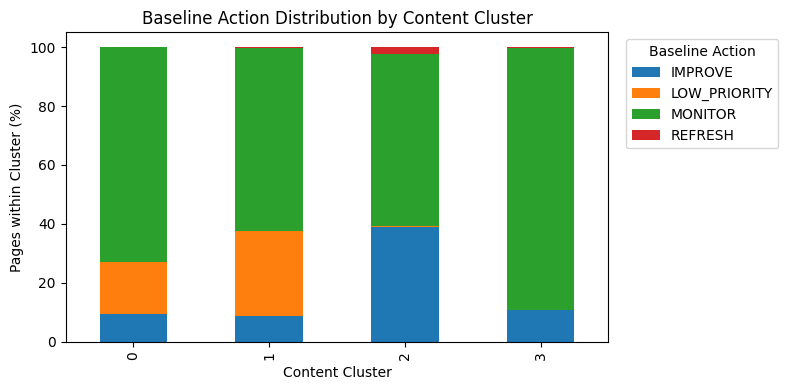

In [17]:
# Purpose: Visualize the percentage distribution of baseline actions
# within each content archetype for the capstone paper.

import matplotlib.pyplot as plt

action_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 4)
)

plt.title("Baseline Action Distribution by Content Cluster")
plt.xlabel("Content Cluster")
plt.ylabel("Pages within Cluster (%)")
plt.legend(title="Baseline Action", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 5. Limitations

1. **Single-month performance window:** The analysis uses March 2026 data, so the clusters may not represent long-term content performance or seasonal patterns.

2. **Limited cluster separation:** The sampled test silhouette score was 0.2514. This suggests some structure in the data, but the clusters may overlap and should not be treated as perfectly distinct content categories.

3. **No ground-truth action labels:** The Week 4 baseline is a rule-based heuristic, not a verified set of correct actions. The comparison shows recommendation distributions, not which approach is more accurate.

4. **Incomplete analytics coverage:** Only pages with available GSC data were included in clustering. Pages without GSC availability may have different characteristics and are not represented in the resulting archetypes.

5. **No causal conclusions:** The analysis cannot establish that refreshing or improving a page will increase impressions, clicks, or rankings.

6. **Operational eligibility is not fully captured by clusters:** Before acting on a recommendation, teams should check publication status, deletion status, business priorities, and content quality.

7. **Client-level generalization remains uncertain:** The test set contains held-out clients, but results from one split do not establish that the same archetypes will generalize to every client or future period.

### Honest Interpretation

These clusters are exploratory, data-driven groups intended to support content review and prioritization. They should guide further investigation rather than automatically determine which pages to refresh, improve, monitor, or deprioritize.

## 6. Ranked recommendations

### Priority 1 — Review High-Visibility Content (Cluster 1)

**Evidence:** Median impressions were 3,635, median clicks were 10, and median CTR was 0.3%.

**Recommended action:** Review search snippets, title relevance, search intent alignment, and content quality. Prioritize pages with substantial impressions but weak click-through performance for manual review.

**Success measure:** Track changes in CTR, clicks, and impressions after any approved updates. Do not assume improvements will occur automatically.

### Priority 2 — Review Commercial and Transactional Content (Cluster 2)

**Evidence:** 55.7% of pages had commercial or transactional intent, and 38.9% received an IMPROVE recommendation from the existing baseline.

**Recommended action:** Check whether pages satisfy user intent, provide useful comparisons or product information, and include clear next steps. Review high-demand pages before low-demand pages.

**Success measure:** Monitor relevant engagement and conversion metrics where available.

### Priority 3 — Audit Low-Visibility Informational Content (Cluster 0)

**Evidence:** Median impressions were 80, and 82.5% of pages had informational intent.

**Recommended action:** Check indexing, search intent alignment, content completeness, duplication, and demand. Refresh pages with clear value and demand; consider merging or retiring content only after a manual review.

**Success measure:** Track eligible pages' impressions, clicks, and useful engagement over time.

### Priority 4 — Investigate Feedly-Heavy, Very-Low-Visibility Content (Cluster 3)

**Evidence:** 73.6% of pages were Feedly articles, and median impressions were 2.

**Recommended action:** Review the purpose, freshness, duplication, and business value of these pages. Check whether low search visibility is expected for their intended distribution channel before recommending any changes.

**Success measure:** Assess whether each page meets its intended purpose rather than relying on search impressions alone.

### Operational Safeguards

Before applying any recommendation:

- Confirm that the page is published, not deleted, and eligible for action.
- Consider business value, content quality, and user intent.
- Use human review before merging, pruning, or making substantial changes.
- Record a baseline and monitor outcomes after changes.
- Treat cluster membership as a prioritization signal, not an automatic decision.

### Recommended Rollout

Start with a small, manually reviewed pilot. Compare outcomes over a defined monitoring period and refine the playbook before expanding it across the inventory.

## 7. Artifacts the paper embeds

The research paper will include the following artifacts to communicate the clustering methodology, results, and practical implications.

### Artifact 1: Dataset and Evaluation Summary

A compact table reporting:
- Total pages with available March 2026 GSC data: 176,738
- Training set: 138,310 pages across 37 clients
- Test set: 38,428 pages across 10 held-out clients
- Clustering algorithm: MiniBatch K-Means
- Number of clusters: 4
- Sampled test silhouette score: 0.2514

### Artifact 2: Cluster Profile Table

A table comparing the four clusters using page count, median impressions, median clicks, median CTR, median search volume, median word count, and dominant content characteristics.

This table will support the interpretation and naming of each content archetype.

### Artifact 3: Baseline Action Distribution Chart

A stacked bar chart showing the percentage distribution of the Week 4 baseline actions—IMPROVE, LOW_PRIORITY, MONITOR, and REFRESH—within each cluster.

The chart illustrates how the existing rule-based recommendations vary across the discovered archetypes. It does not measure recommendation accuracy.

### Artifact 4: Ranked Recommendation Playbook

A table mapping each cluster to its observed characteristics, proposed review action, and suggested monitoring metrics. Recommendations will be presented as human-reviewed decision support rather than automatic instructions.

### Artifact 5: Limitations and Responsible Use

The paper will explicitly report the single-month observation window, incomplete GSC coverage, limited cluster separation, lack of ground-truth action labels, and inability to establish causal effects.

### Data Attribution

The paper will include the attribution: **Built on the FlyRank ML Internship dataset**, linked to https://flyrank.ai.

Only aggregated, public-safe results will be published. Client identities, domains, URLs, private search queries, credentials, and raw exports will not be included.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.